# MLP: от NumPy к PyTorch

## 1. Setup & EDA

Загрузим 1%-ную подвыборку Quick, Draw!, соберём сбалансированный набор и проведём первичный анализ данных.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split

# Единый seed делает случайные операции воспроизводимыми.
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = Path("data/project/quickdraw_bitmap")
SUBSET_PATH = Path("data/project/quickdraw_subset_1000.npz")
MAX_PER_CLASS = 1000

### Загрузка данных

Архив из задания хранится в формате TensorFlow Snapshot. Соберём по 1000 изображений каждого класса и сохраним результат в кэш для быстрых повторных запусков.

In [2]:
# --- 1. Проверка пути к данным ---
# До начала загрузки убеждаемся, что архив был распакован в ожидаемую папку.
# Явная ошибка с полным путём быстрее объяснит проблему, чем ошибка TensorFlow ниже по коду.
if not DATA_DIR.exists():
    raise FileNotFoundError(f"Папка не найдена: {DATA_DIR.resolve()}")

# --- 2. Проверка состава архива ---
# Рекурсивно находим все файлы TensorFlow Snapshot. Сортировка делает вывод стабильным
# на разных запусках, а размеры файлов помогают убедиться, что основной файл с данными не пуст.
snapshot_files = sorted(path for path in DATA_DIR.rglob("*") if path.is_file())
print("Файлы исходного датасета:")
for path in snapshot_files:
    print(f"  {path.relative_to(DATA_DIR)} — {path.stat().st_size / 1024**2:.2f} MB")

# --- 3. Загрузка названий классов ---
# В snapshot хранятся только числовые метки 0–344. Метаданные TFDS дают им читаемые названия.
# Индекс в class_names точно совпадает с меткой: например, class_names[12] — это имя класса с меткой 12.
builder = tfds.builder("quickdraw_bitmap")
class_names = builder.info.features["label"].names
num_classes = len(class_names)

# --- 4. Быстрая загрузка ранее собранной подвыборки ---
# Первая обработка snapshot занимает время, поэтому её результат хранится в сжатом NPZ-файле.
# Если кэш уже существует, извлекаем из него готовые массивы изображений X и меток y.
if SUBSET_PATH.exists():
    with np.load(SUBSET_PATH) as cached_data:
        X, y = cached_data["X"], cached_data["y"]
    print(f"\nПодвыборка загружена из кэша: {SUBSET_PATH}")
else:
    # --- 5. Чтение TensorFlow Snapshot и подготовка накопителей ---
    # Эта ветка выполняется только один раз, когда кэша ещё нет. images_by_class хранит отдельный
    # список изображений для каждого класса, а class_counts отслеживает, сколько примеров уже собрано.
    dataset = tf.data.Dataset.load(str(DATA_DIR))
    images_by_class = [[] for _ in range(num_classes)]
    class_counts = np.zeros(num_classes, dtype=np.int64)

    # --- 6. Сбор сбалансированной подвыборки ---
    # Последовательно читаем примеры и берём не более MAX_PER_CLASS изображений каждого класса.
    # Исходная форма (28, 28, 1) содержит лишнюю ось grayscale-канала; squeeze преобразует её в (28, 28).
    # Сканирование прекращается сразу после набора нужного числа примеров всех классов.
    for sample in dataset.as_numpy_iterator():
        label = int(sample["label"])
        if class_counts[label] < MAX_PER_CLASS:
            images_by_class[label].append(np.squeeze(sample["image"], axis=-1))
            class_counts[label] += 1
        if np.all(class_counts == MAX_PER_CLASS):
            break

    # --- 7. Проверка полноты подвыборки ---
    # Не продолжаем работу с неполными данными: в ошибке будут указаны ID классов, которым не хватило примеров.
    if np.any(class_counts < MAX_PER_CLASS):
        missing = np.flatnonzero(class_counts < MAX_PER_CLASS)
        raise ValueError(f"Недостаточно примеров для классов: {missing.tolist()}")

    # --- 8. Формирование массивов X/y и сохранение кэша ---
    # stack собирает картинки одного класса, а concatenate объединяет все 345 классов в общий массив X.
    # Поскольку X собран по классам, repeat создаёт соответствующую последовательность меток y.
    # np.savez_compressed существенно уменьшает размер кэша без изменения самих данных.
    X = np.concatenate([np.stack(images) for images in images_by_class])
    y = np.repeat(np.arange(num_classes, dtype=np.int64), MAX_PER_CLASS)
    np.savez_compressed(SUBSET_PATH, X=X, y=y)
    print(f"\nПодвыборка сохранена: {SUBSET_PATH}")

Файлы исходного датасета:
  .DS_Store — 0.01 MB
  5081042506959188152/.DS_Store — 0.01 MB
  5081042506959188152/00000000.shard/00000000.snapshot — 408.29 MB
  dataset_spec.pb — 0.00 MB
  snapshot.metadata — 0.00 MB



Подвыборка загружена из кэша: data/project/quickdraw_subset_1000.npz


### Проверка загруженных массивов

Проверим форму, тип данных и диапазон пикселей, а также убедимся, что метки имеют ожидаемый формат и охватывают все классы из `class_names`.

In [3]:
# До препроцессинга проверяем единые исходные массивы X/y.
# X должен содержать grayscale-изображения 28×28, а y — одну целочисленную метку на изображение.
print("Характеристики исходных массивов:")
for name, array in {"X": X, "y": y}.items():
    print(
        f"  {name}: shape={str(array.shape):17s} dtype={str(array.dtype):7s} min={array.min()} max={array.max()}"
    )

unique_labels = np.unique(y)
assert X.ndim == 3 and X.shape[1:] == (28, 28)
assert y.ndim == 1 and len(X) == len(y)
assert X.dtype == np.uint8 and y.dtype == np.int64
assert len(unique_labels) == len(class_names) == num_classes
assert np.array_equal(unique_labels, np.arange(num_classes))
print(f"\nЧисло классов: {num_classes}")
print("Проверки форм, типов и меток пройдены.")

Характеристики исходных массивов:
  X: shape=(345000, 28, 28)  dtype=uint8   min=0 max=255
  y: shape=(345000,)         dtype=int64   min=0 max=344

Число классов: 345
Проверки форм, типов и меток пройдены.


### Примеры изображений

Покажем 12 случайных рисунков из исходной подвыборки с читаемыми названиями классов.

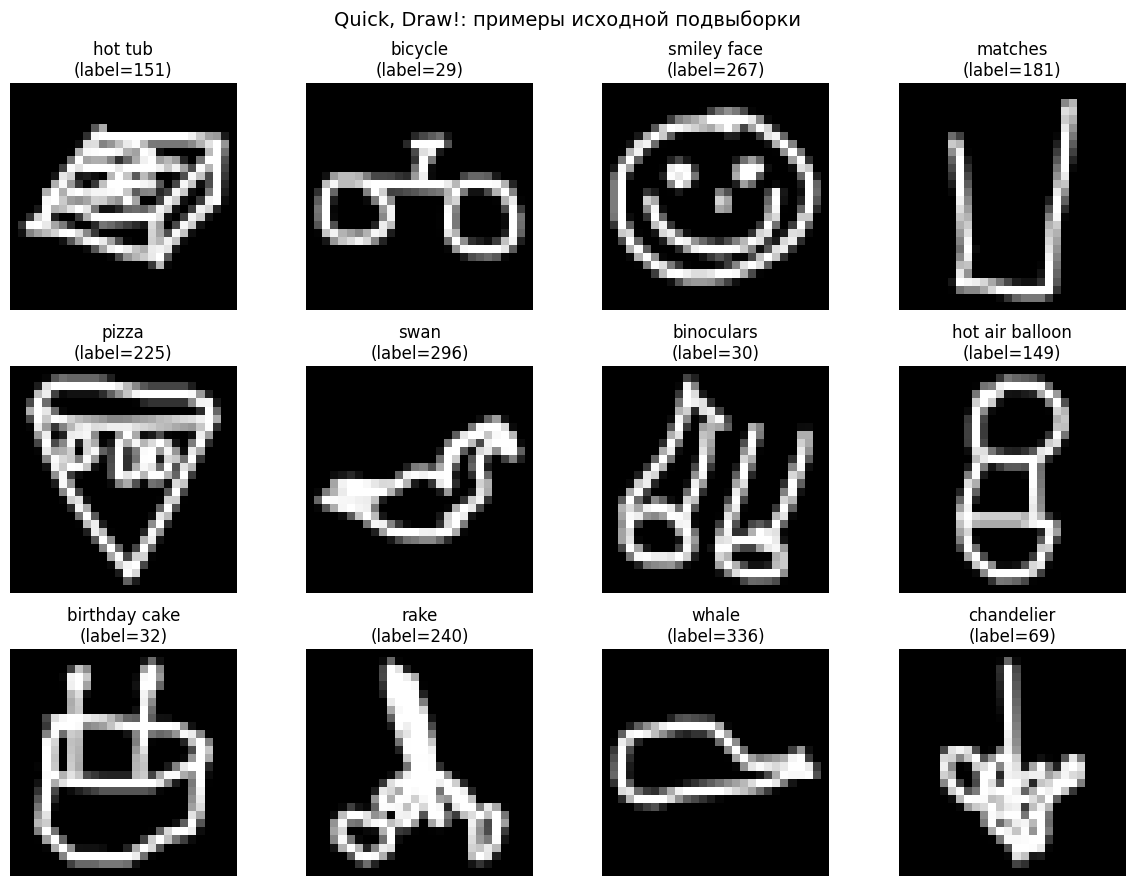

In [4]:
rng = np.random.default_rng(SEED)
example_indices = rng.choice(len(X), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for axis, index in zip(axes.ravel(), example_indices):
    label = int(y[index])
    axis.imshow(X[index], cmap="gray", vmin=0, vmax=255)
    axis.set_title(f"{class_names[label]}\n(label={label})")
    axis.axis("off")
fig.suptitle("Quick, Draw!: примеры исходной подвыборки", fontsize=14)
plt.tight_layout()
plt.show()

### Распределение классов

Проверим число примеров каждого класса до разбиения. Благодаря ограничению `MAX_PER_CLASS` все классы представлены поровну.

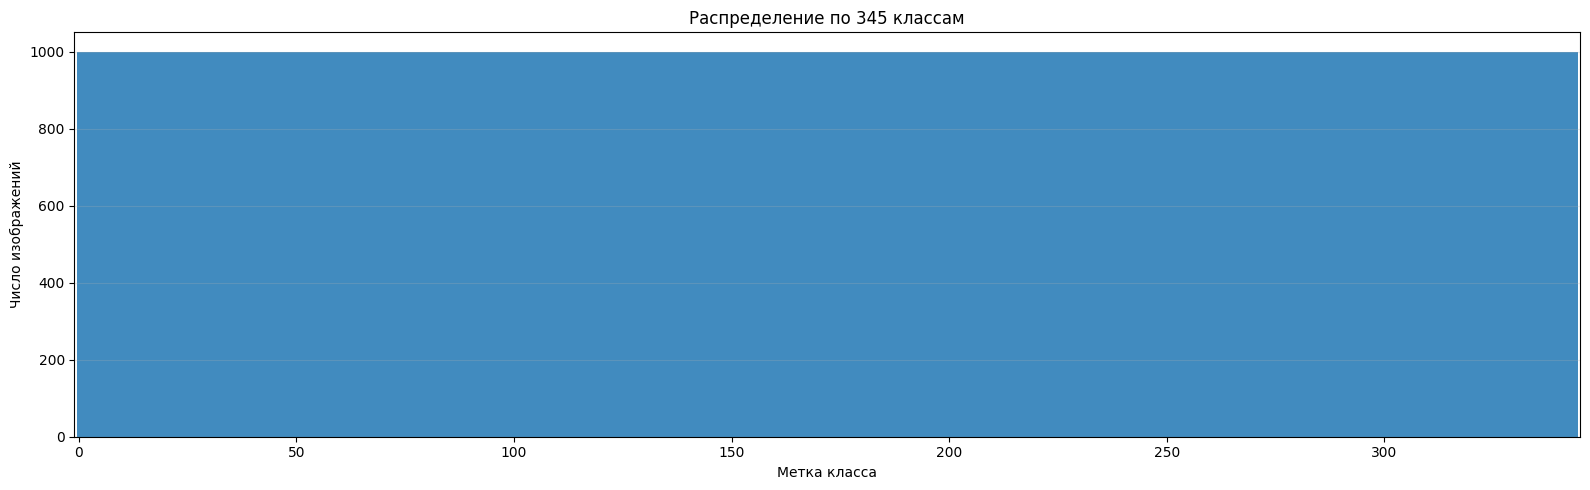

Подвыборка: 1000–1000 примеров на класс


In [5]:
class_counts = np.bincount(y, minlength=num_classes)
class_ids = np.arange(num_classes)

fig, axis = plt.subplots(figsize=(16, 5))
axis.bar(class_ids, class_counts, width=1.0, color="tab:blue", alpha=0.85)
axis.set(
    title="Распределение по 345 классам",
    xlabel="Метка класса",
    ylabel="Число изображений",
)
axis.set_xlim(-1, num_classes)
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Подвыборка: {class_counts.min()}–{class_counts.max()} примеров на класс")

## 2. Препроцессинг

Разделим исходную подвыборку на train/validation/test в пропорции 80/10/10. После разбиения изменим размер изображений с `28×28` до `32×32`, приведём их к `float32` и нормализуем пиксели в диапазон `[0, 1]`.

In [6]:
# --- 1. Настройка долей выборок ---
# Сумма долей должна быть равна 1.0: 80% оставляем для обучения, по 10% — для validation и test.
TRAIN_SIZE = 0.8
VAL_SIZE = 0.1
TEST_SIZE = 0.1
assert np.isclose(TRAIN_SIZE + VAL_SIZE + TEST_SIZE, 1.0)

# --- 2. Первое разбиение: train и временная выборка ---
# stratify=y сохраняет одинаковые доли всех 345 классов, а random_state делает разбиение воспроизводимым.
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=VAL_SIZE + TEST_SIZE, random_state=SEED, shuffle=True, stratify=y
)

# --- 3. Второе разбиение: validation и test ---
# Временную 20%-ную часть делим пополам, поэтому относительная доля test внутри неё равна 0.5.
relative_test_size = TEST_SIZE / (VAL_SIZE + TEST_SIZE)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw,
    y_temp,
    test_size=relative_test_size,
    random_state=SEED,
    shuffle=True,
    stratify=y_temp,
)

# --- 4. Проверка сырого разбиения ---
# Каждый исходный объект должен попасть ровно в одну выборку, а в каждой выборке должны остаться все классы.
assert len(X_train_raw) + len(X_val_raw) + len(X_test_raw) == len(X)
assert all(len(np.unique(labels)) == num_classes for labels in (y_train, y_val, y_test))

print(f"Train raw:      X={X_train_raw.shape}, y={y_train.shape}")
print(f"Validation raw: X={X_val_raw.shape}, y={y_val.shape}")
print(f"Test raw:       X={X_test_raw.shape}, y={y_test.shape}")

Train raw:      X=(276000, 28, 28), y=(276000,)
Validation raw: X=(34500, 28, 28), y=(34500,)
Test raw:       X=(34500, 28, 28), y=(34500,)


### Изменение размера и нормализация

Преобразуем изображения каждой выборки из `28×28` в `32×32`, приведём их к `float32` и нормализуем значения пикселей в диапазон `[0, 1]`.

In [7]:
# --- 5. Функция resize и нормализации ---
def resize_and_normalize(images, target_size=(32, 32), batch_size=2048):
    """
    Изменяет размер grayscale-изображений и нормализует пиксели в [0, 1].

    Обработка батчами не создаёт большую временную TensorFlow-копию всего датасета.
    Bilinear interpolation плавно переносит штрихи с сетки 28×28 на сетку 32×32.
    """
    processed = np.empty((len(images), *target_size), dtype=np.float32)

    for start in range(0, len(images), batch_size):
        stop = min(start + batch_size, len(images))
        # tf.image.resize ожидает ось канала, поэтому временно добавляем её в конце.
        batch = tf.convert_to_tensor(images[start:stop, ..., np.newaxis])
        resized = tf.image.resize(batch, target_size, method="bilinear", antialias=True)
        # Деление на 255 переводит исходный диапазон uint8 [0, 255] в float32 [0, 1].
        processed[start:stop] = resized.numpy()[..., 0] / np.float32(255.0)

    return processed


# --- 6. Одинаковая предобработка трёх выборок ---
# Метки y не изменяются: resize и нормализация применяются только к изображениям.
X_train = resize_and_normalize(X_train_raw)
X_val = resize_and_normalize(X_val_raw)
X_test = resize_and_normalize(X_test_raw)

# --- 7. Проверка готовых артефактов ---
processed_splits = {"X_train": X_train, "X_val": X_val, "X_test": X_test}
for name, images in processed_splits.items():
    assert images.shape[1:] == (32, 32)
    assert images.dtype == np.float32
    assert 0.0 <= images.min() <= images.max() <= 1.0
    print(
        f"{name:7s}: shape={str(images.shape):18s} dtype={images.dtype} range=[{images.min():.3f}, {images.max():.3f}]"
    )

print(f"y_train: shape={y_train.shape}, dtype={y_train.dtype}")
print(f"y_val:   shape={y_val.shape}, dtype={y_val.dtype}")
print(f"y_test:  shape={y_test.shape}, dtype={y_test.dtype}")

X_train: shape=(276000, 32, 32)   dtype=float32 range=[0.000, 1.000]
X_val  : shape=(34500, 32, 32)    dtype=float32 range=[0.000, 1.000]
X_test : shape=(34500, 32, 32)    dtype=float32 range=[0.000, 1.000]
y_train: shape=(276000,), dtype=int64
y_val:   shape=(34500,), dtype=int64
y_test:  shape=(34500,), dtype=int64


### Sanity-check: до и после препроцессинга

Сравним одни и те же примеры до и после преобразования. Проверка должна подтвердить, что форма и диапазон пикселей изменились, а сами рисунки и их метки остались корректными.

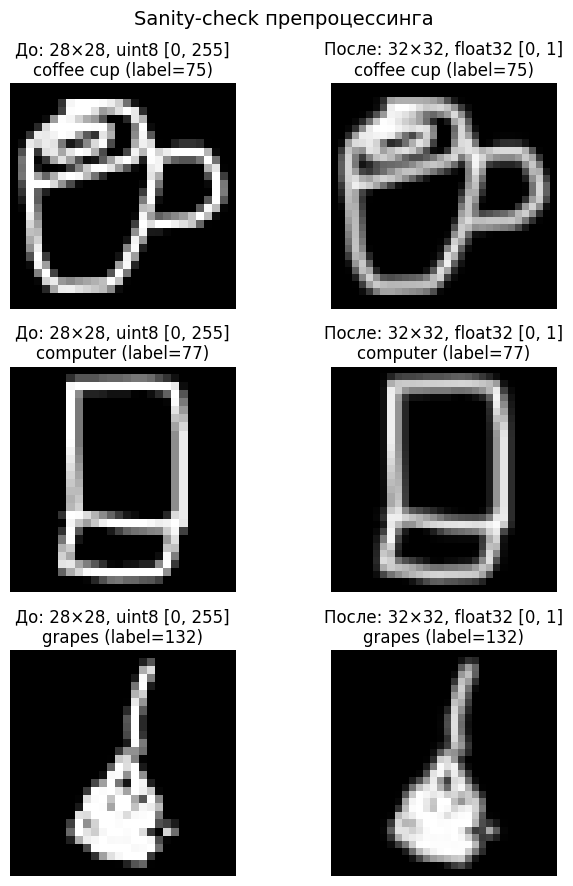

Численная проверка первого примера:
  До:    shape=(28, 28), dtype=uint8, range=[0, 255]
  После: shape=(32, 32), dtype=float32, range=[0.000, 1.000]
  Метка не изменилась: 75 (coffee cup)


In [8]:
# Используем три фиксированных случайных индекса, чтобы результат был воспроизводимым.
sanity_indices = np.random.default_rng(SEED).choice(len(X_train), size=3, replace=False)
fig, axes = plt.subplots(len(sanity_indices), 2, figsize=(7, 9))

for row, index in enumerate(sanity_indices):
    label = int(y_train[index])
    axes[row, 0].imshow(X_train_raw[index], cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(
        f"До: 28×28, uint8 [0, 255]\n{class_names[label]} (label={label})"
    )
    axes[row, 1].imshow(X_train[index], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title(
        f"После: 32×32, float32 [0, 1]\n{class_names[label]} (label={label})"
    )
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.suptitle("Sanity-check препроцессинга", fontsize=14)
plt.tight_layout()
plt.show()

check_index = int(sanity_indices[0])
print("Численная проверка первого примера:")
print(
    f"  До:    shape={X_train_raw[check_index].shape}, dtype={X_train_raw.dtype}, range=[{X_train_raw[check_index].min()}, {X_train_raw[check_index].max()}]"
)
print(
    f"  После: shape={X_train[check_index].shape}, dtype={X_train.dtype}, range=[{X_train[check_index].min():.3f}, {X_train[check_index].max():.3f}]"
)
print(
    f"  Метка не изменилась: {y_train[check_index]} ({class_names[y_train[check_index]]})"
)

## 3. MLP на NumPy

Реализуем полносвязную сеть без DL-фреймворков: инициализацию весов, forward/backward, stable softmax + cross-entropy, SGD и Adam. Архитектура задаётся списком `layer_sizes`, а скрытая активация может быть `relu` или `tanh`.

### Основные элементы и этапы обучения

1. **Инициализация параметров.** Для каждой пары соседних слоёв создаются матрица весов `W` и вектор смещений `b`. He initialization используется вместе с ReLU, а Xavier — с Tanh. Их масштаб зависит от числа входов слоя (`fan_in`), поэтому сигнал и градиенты с меньшей вероятностью будут затухать или взрываться при прохождении через сеть. Смещения в начале равны нулю.
2. **Прямой проход (`forward`).** В каждом слое вычисляется линейное преобразование `z = a @ W + b`, после которого на скрытых слоях применяется ReLU или Tanh. Последний слой возвращает необработанные оценки классов — `logits`. Промежуточные активации и `z` сохраняются в `cache` для обратного прохода.
3. **Функция потерь.** Из logits вычисляются вероятности с помощью softmax и средняя cross-entropy. Перед `exp` из каждой строки вычитается её максимум, а аргумент `log` ограничивается снизу: эти меры защищают вычисления от переполнения и `log(0)`.
4. **Обратный проход (`backward`).** Градиент ошибки распространяется от выходного слоя к первому по правилу цепочки. Для каждого слоя вычисляются `dW` и `db`, а для скрытых слоёв дополнительно учитывается производная выбранной функции активации.
5. **Оптимизация.** `step_sgd()` обновляет параметры обычным градиентным спуском. `step_adam()` хранит собственные состояния `m`, `v`, `t`, корректирует смещение моментов и адаптирует величину шага для каждого параметра. В основном запуске используется Adam; L2-регуляризация ограничивает чрезмерный рост весов, а снижение learning rate делает обновления осторожнее на плато.
6. **Валидация.** После каждой эпохи модель выполняет только прямой проход по `X_val`: параметры при этом не обновляются. Рассчитываются `val_loss` и `val_acc`; по `val_acc` сохраняется лучшее состояние и принимается решение об early stopping. Тестовая выборка не участвует ни в обучении, ни в выборе лучшей эпохи.

In [9]:
import json
import time


class NumpyMLP:
    """Конфигурируемый многослойный персептрон, реализованный на NumPy."""

    def __init__(self, layer_sizes, activation="relu", init="he", seed=42):
        if len(layer_sizes) < 2:
            raise ValueError("layer_sizes должен содержать как минимум input_dim и output_dim")
        if activation not in {"relu", "tanh"}:
            raise ValueError("activation должна быть 'relu' или 'tanh'")
        if init not in {"he", "xavier"}:
            raise ValueError("init должен быть 'he' или 'xavier'")

        self.layer_sizes = list(map(int, layer_sizes))
        self.activation_name = activation
        self.init_name = init
        self.rng = np.random.default_rng(seed)

        # weights[i] и biases[i] описывают линейное преобразование между соседними размерами.
        self.weights = []
        self.biases = []
        for fan_in, fan_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            # He лучше сохраняет масштаб сигнала с ReLU; Xavier естественен для tanh.
            scale = np.sqrt(2.0 / fan_in) if init == "he" else np.sqrt(2.0 / (fan_in + fan_out))
            self.weights.append(self.rng.normal(0.0, scale, (fan_in, fan_out)).astype(np.float32))
            self.biases.append(np.zeros((1, fan_out), dtype=np.float32))

        self.cache = []
        self.grad_weights = [np.zeros_like(weight) for weight in self.weights]
        self.grad_biases = [np.zeros_like(bias) for bias in self.biases]

        # Adam хранит скользящие средние градиентов (m), их квадратов (v) и номер шага t.
        self.adam_m_w = [np.zeros_like(weight) for weight in self.weights]
        self.adam_v_w = [np.zeros_like(weight) for weight in self.weights]
        self.adam_m_b = [np.zeros_like(bias) for bias in self.biases]
        self.adam_v_b = [np.zeros_like(bias) for bias in self.biases]
        self.adam_t = 0

    def _activation(self, values):
        return np.maximum(values, 0.0) if self.activation_name == "relu" else np.tanh(values)

    def _activation_derivative(self, preactivation):
        if self.activation_name == "relu":
            return (preactivation > 0.0).astype(np.float32)
        tanh_values = np.tanh(preactivation)
        return 1.0 - tanh_values * tanh_values

    def forward(self, inputs):
        """Computes logits and caches intermediate tensors required by backward()."""
        activations = np.asarray(inputs, dtype=np.float32)
        self.cache = []

        for layer_index, (weight, bias) in enumerate(zip(self.weights, self.biases)):
            preactivation = activations @ weight + bias
            self.cache.append((activations, preactivation))
            # Последний слой возвращает logits: softmax вычисляется в loss для численной стабильности.
            activations = (
                preactivation
                if layer_index == len(self.weights) - 1
                else self._activation(preactivation)
            )
        return activations

    @staticmethod
    def softmax_cross_entropy(logits, labels):
        """Returns mean cross-entropy and stable class probabilities."""
        labels = np.asarray(labels, dtype=np.int64)
        # Вычитание максимума не меняет softmax, но предотвращает overflow в exp.
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        exp_values = np.exp(shifted)
        probabilities = exp_values / np.sum(exp_values, axis=1, keepdims=True)
        true_probabilities = probabilities[np.arange(len(labels)), labels]
        loss = -np.mean(np.log(np.clip(true_probabilities, 1e-12, 1.0)))
        return float(loss), probabilities

    def backward(self, probabilities, labels):
        """Backpropagates the softmax-cross-entropy gradient through all layers."""
        labels = np.asarray(labels, dtype=np.int64)
        gradient = probabilities.copy()
        gradient[np.arange(len(labels)), labels] -= 1.0
        gradient /= len(labels)

        for layer_index in reversed(range(len(self.weights))):
            previous_activations, preactivation = self.cache[layer_index]
            self.grad_weights[layer_index] = previous_activations.T @ gradient
            self.grad_biases[layer_index] = np.sum(gradient, axis=0, keepdims=True)
            if layer_index > 0:
                gradient = gradient @ self.weights[layer_index].T
                gradient *= self._activation_derivative(self.cache[layer_index - 1][1])

    def step_sgd(self, learning_rate):
        """Updates parameters using vanilla stochastic gradient descent."""
        for index in range(len(self.weights)):
            self.weights[index] -= learning_rate * self.grad_weights[index]
            self.biases[index] -= learning_rate * self.grad_biases[index]

    def step_adam(self, learning_rate=1e-3, beta1=0.9, beta2=0.999, epsilon=1e-8):
        """Updates parameters using Adam with bias-corrected first and second moments."""
        self.adam_t += 1
        for index in range(len(self.weights)):
            for gradient, moment, variance, parameter in (
                (self.grad_weights[index], self.adam_m_w[index], self.adam_v_w[index], self.weights[index]),
                (self.grad_biases[index], self.adam_m_b[index], self.adam_v_b[index], self.biases[index]),
            ):
                moment *= beta1
                moment += (1.0 - beta1) * gradient
                variance *= beta2
                variance += (1.0 - beta2) * gradient * gradient
                corrected_moment = moment / (1.0 - beta1**self.adam_t)
                corrected_variance = variance / (1.0 - beta2**self.adam_t)
                parameter -= learning_rate * corrected_moment / (np.sqrt(corrected_variance) + epsilon)

    def get_state(self):
        return ([weight.copy() for weight in self.weights], [bias.copy() for bias in self.biases])

    def set_state(self, state):
        self.weights = [weight.copy() for weight in state[0]]
        self.biases = [bias.copy() for bias in state[1]]

    def save(self, path):
        """Saves architecture and learned parameters to a compressed NPZ file."""
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        payload = {
            "metadata": np.array(json.dumps({"layer_sizes": self.layer_sizes, "activation": self.activation_name, "init": self.init_name})),
        }
        for index, (weight, bias) in enumerate(zip(self.weights, self.biases)):
            payload[f"weight_{index}"] = weight
            payload[f"bias_{index}"] = bias
        np.savez_compressed(path, **payload)

    @classmethod
    def load(cls, path):
        """Restores architecture and learned parameters from save()."""
        with np.load(path) as payload:
            metadata = json.loads(payload["metadata"].item())
            model = cls(metadata["layer_sizes"], metadata["activation"], metadata["init"])
            for index in range(len(model.weights)):
                model.weights[index] = payload[f"weight_{index}"].copy()
                model.biases[index] = payload[f"bias_{index}"].copy()
        return model

### Функции обучения и валидации NumPy

Определим validation loop и mini-batch train loop: прямой проход, расчёт loss, обратный проход, обновление параметров, логирование метрик и восстановление лучших весов.

In [10]:
def evaluate_numpy(model, features, labels, batch_size=2048):
    """Computes mean loss and accuracy in batches to keep memory usage bounded."""
    total_loss = 0.0
    total_correct = 0
    for start in range(0, len(features), batch_size):
        stop = min(start + batch_size, len(features))
        logits = model.forward(features[start:stop])
        batch_loss, probabilities = model.softmax_cross_entropy(logits, labels[start:stop])
        total_loss += batch_loss * (stop - start)
        total_correct += np.sum(np.argmax(probabilities, axis=1) == labels[start:stop])
    return total_loss / len(features), total_correct / len(features)


def train_numpy(
    model,
    X_train_flat,
    y_train,
    X_val_flat,
    y_val,
    epochs=50,
    batch_size=256,
    learning_rate=1e-3,
    optimizer="adam",
    patience=12,
    weight_decay=1e-4,
    lr_decay=0.5,
    seed=42,
):
    """Runs mini-batch training, logs each epoch and restores the best validation state."""
    if optimizer not in {"sgd", "adam"}:
        raise ValueError("optimizer должен быть 'sgd' или 'adam'")

    rng = np.random.default_rng(seed)
    current_learning_rate = learning_rate
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best_state = model.get_state()
    best_val_acc = -np.inf
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        permutation = rng.permutation(len(X_train_flat))
        train_loss_sum = 0.0

        # Один шаг mini-batch обучения: forward → loss → backward → update.
        for start in range(0, len(X_train_flat), batch_size):
            batch_indices = permutation[start : start + batch_size]
            logits = model.forward(X_train_flat[batch_indices])
            batch_loss, probabilities = model.softmax_cross_entropy(logits, y_train[batch_indices])
            model.backward(probabilities, y_train[batch_indices])
            # L2-регуляризация сдерживает рост весов и уменьшает переобучение.
            if weight_decay > 0.0:
                for layer_index in range(len(model.weights)):
                    model.grad_weights[layer_index] += weight_decay * model.weights[layer_index]
            if optimizer == "adam":
                model.step_adam(learning_rate=current_learning_rate)
            else:
                model.step_sgd(learning_rate=current_learning_rate)
            train_loss_sum += batch_loss * len(batch_indices)

        train_loss = train_loss_sum / len(X_train_flat)
        # Валидация выполняет только forward: градиенты и параметры модели не изменяются.
        val_loss, val_acc = evaluate_numpy(model, X_val_flat, y_val)
        epoch_time = time.perf_counter() - epoch_start
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)
        print(f"Epoch {epoch:02d}/{epochs} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | lr={current_learning_rate:.1e} | time={epoch_time:.2f}s")

        # Early stopping сокращает расходы CPU и возвращает параметры с лучшим val_acc.
        if val_acc > best_val_acc + 1e-4:
            best_val_acc = val_acc
            best_state = model.get_state()
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            # При плато val_acc делаем меньшие шаги, чтобы точнее настроить параметры.
            if epochs_without_improvement % 4 == 0:
                current_learning_rate *= lr_decay
                print(f"  Learning rate reduced to {current_learning_rate:.1e}")
            if epochs_without_improvement >= patience:
                print(f"Early stopping: val_acc не улучшался {patience} эпох.")
                break

    model.set_state(best_state)
    return history

### Обучение NumPy MLP

Используем одинаковую для обеих будущих реализаций архитектуру `1024 → 512 → 256 → 345`. Скрытые слои используют ReLU и He initialization. Максимальный бюджет обучения установлен равным **50 эпохам**, что соответствует рекомендованному в задании диапазону 50–100 эпох. При этом используется `early stopping`: если `val_acc` длительное время не улучшается, обучение корректно завершается раньше и восстанавливаются параметры лучшей эпохи. Поэтому фактическое число выполненных эпох может оказаться меньше 50 — это результат защиты от переобучения и лишних вычислений, а не изменение заданного максимума.

In [11]:
# Flatten преобразует каждое изображение 32×32 в вектор из 1024 признаков.
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

LAYER_SIZES = [X_train_flat.shape[1], 512, 256, num_classes]
numpy_model = NumpyMLP(LAYER_SIZES, activation="relu", init="he", seed=SEED)
numpy_history = train_numpy(
    numpy_model,
    X_train_flat,
    y_train,
    X_val_flat,
    y_val,
    epochs=50,
    batch_size=256,
    learning_rate=1e-3,
    optimizer="adam",
    patience=12,
    weight_decay=1e-4,
    lr_decay=0.5,
    seed=SEED,
)

numpy_val_loss, numpy_val_acc = evaluate_numpy(numpy_model, X_val_flat, y_val)
numpy_test_loss, numpy_test_acc = evaluate_numpy(numpy_model, X_test_flat, y_test)
print(f"\nЛучшая NumPy-модель: val_acc={numpy_val_acc:.4f}, test_acc={numpy_test_acc:.4f}")

# Сохраняем модель и проверяем, что загруженная копия даёт те же logits.
NUMPY_MODEL_PATH = Path("artifacts/numpy_mlp.npz")
numpy_model.save(NUMPY_MODEL_PATH)
numpy_model_loaded = NumpyMLP.load(NUMPY_MODEL_PATH)
assert np.allclose(numpy_model.forward(X_val_flat[:32]), numpy_model_loaded.forward(X_val_flat[:32]))
print(f"Модель сохранена и успешно загружена: {NUMPY_MODEL_PATH}")

Epoch 01/50 | train_loss=3.8151 | val_loss=3.2442 | val_acc=0.3017 | lr=1.0e-03 | time=7.77s


Epoch 02/50 | train_loss=2.9847 | val_loss=2.9031 | val_acc=0.3609 | lr=1.0e-03 | time=7.59s


Epoch 03/50 | train_loss=2.6779 | val_loss=2.7254 | val_acc=0.3965 | lr=1.0e-03 | time=7.29s


Epoch 04/50 | train_loss=2.4993 | val_loss=2.6361 | val_acc=0.4116 | lr=1.0e-03 | time=6.45s


Epoch 05/50 | train_loss=2.3697 | val_loss=2.5810 | val_acc=0.4239 | lr=1.0e-03 | time=6.62s


...

Epoch 43/50 | train_loss=1.1491 | val_loss=2.5591 | val_acc=0.4631 | lr=3.1e-05 | time=6.04s


Epoch 44/50 | train_loss=1.1474 | val_loss=2.5593 | val_acc=0.4618 | lr=3.1e-05 | time=6.09s


Epoch 45/50 | train_loss=1.1461 | val_loss=2.5611 | val_acc=0.4624 | lr=3.1e-05 | time=6.30s


Epoch 46/50 | train_loss=1.1449 | val_loss=2.5620 | val_acc=0.4620 | lr=3.1e-05 | time=6.02s
  Learning rate reduced to 1.6e-05
Early stopping: val_acc не улучшался 12 эпох.



Лучшая NumPy-модель: val_acc=0.4637, test_acc=0.4585
Модель сохранена и успешно загружена: artifacts/numpy_mlp.npz


## 4. MLP на PyTorch

Воспроизведём NumPy-архитектуру на PyTorch. `QuickDrawDataset` преобразует NumPy-массивы в тензоры, `DataLoader` формирует mini-batches, а `TorchMLP` создаёт нужное число `Linear`-слоёв из `layer_sizes`.

### Как устроен цикл PyTorch

1. **Инициализация.** `Linear`-слои получают He/Kaiming initialization для ReLU или Xavier initialization для Tanh, смещения обнуляются. Это соответствует NumPy-версии и помогает сохранять разумный масштаб активаций и градиентов.
2. **Прямой проход.** Вызов `model(features)` последовательно применяет `Linear`-слои и функции активации, возвращая logits. `CrossEntropyLoss` сама объединяет numerically stable log-softmax и cross-entropy, поэтому отдельно применять softmax во время обучения не нужно.
3. **Обратный проход.** `optimizer.zero_grad()` очищает градиенты предыдущего mini-batch, `loss.backward()` запускает автоматическое дифференцирование и вычисляет градиенты всех обучаемых параметров.
4. **Оптимизация.** `optimizer.step()` обновляет веса методом AdamW. Weight decay ограничивает рост весов, а `ReduceLROnPlateau` уменьшает learning rate, когда `val_acc` перестаёт расти. В сочетании с корректной инициализацией и нормализованными входами это снижает риск нестабильных обновлений.
5. **Валидация.** `model.eval()` переводит модель в режим оценки, а `torch.no_grad()` отключает хранение графа градиентов. На validation рассчитываются loss и accuracy без обновления весов; лучшее состояние сохраняется и восстанавливается после early stopping. Test используется только для итоговой независимой оценки.

In [12]:
import copy

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset


# Фиксируем seed и используем CPU для воспроизводимого и честного сравнения с NumPy.
torch.manual_seed(SEED)
LAYER_SIZES = [32 * 32, 512, 256, num_classes]
DEVICE = torch.device("cpu")


class QuickDrawDataset(Dataset):
    """Provides flattened float32 images and int64 labels without copying the full arrays."""

    def __init__(self, images, labels):
        if len(images) != len(labels):
            raise ValueError("images и labels должны иметь одинаковую длину")
        # from_numpy использует общую память с NumPy и не создаёт дорогую копию всего датасета.
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.images[index].reshape(-1), self.labels[index]


class TorchMLP(nn.Module):
    """PyTorch MLP configured by the same layer_sizes convention as NumpyMLP."""

    def __init__(self, layer_sizes, activation="relu", init="he"):
        super().__init__()
        if activation not in {"relu", "tanh"}:
            raise ValueError("activation должна быть 'relu' или 'tanh'")
        if init not in {"he", "xavier"}:
            raise ValueError("init должна быть 'he' или 'xavier'")

        self.layer_sizes = list(map(int, layer_sizes))
        self.activation_name = activation
        self.init_name = init
        activation_layer = nn.ReLU if activation == "relu" else nn.Tanh

        layers = []
        for index, (fan_in, fan_out) in enumerate(zip(self.layer_sizes[:-1], self.layer_sizes[1:])):
            linear = nn.Linear(fan_in, fan_out)
            if init == "he":
                nn.init.kaiming_normal_(linear.weight, nonlinearity="relu")
            else:
                nn.init.xavier_normal_(linear.weight, gain=nn.init.calculate_gain("tanh") if activation == "tanh" else 1.0)
            nn.init.zeros_(linear.bias)
            layers.append(linear)
            if index < len(self.layer_sizes) - 2:
                layers.append(activation_layer())

        self.network = nn.Sequential(*layers)

    def forward(self, inputs):
        return self.network(inputs)


# Одинаковый batch size делает сравнение с NumPy более корректным.
BATCH_SIZE = 256
train_dataset = QuickDrawDataset(X_train, y_train)
val_dataset = QuickDrawDataset(X_val, y_val)
test_dataset = QuickDrawDataset(X_test, y_test)
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=loader_generator, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

sample_features, sample_labels = next(iter(train_loader))
print(f"Mini-batch: features={sample_features.shape} {sample_features.dtype}, labels={sample_labels.shape} {sample_labels.dtype}")

Mini-batch: features=torch.Size([256, 1024]) torch.float32, labels=torch.Size([256]) torch.int64


### Функции обучения и валидации PyTorch

Реализуем оценку модели без вычисления градиентов и цикл обучения с AdamW, scheduler, логированием каждой эпохи и early stopping.

In [13]:
def evaluate_torch(model, data_loader, criterion, device=DEVICE):
    """Evaluates mean loss and accuracy without building an autograd graph."""
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    # На валидации граф вычислений не нужен: веса здесь не обновляются.
    with torch.no_grad():
        for features, labels in data_loader:
            features, labels = features.to(device), labels.to(device)
            logits = model(features)
            loss = criterion(logits, labels)
            total_loss += loss.item() * len(labels)
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_examples += len(labels)
    return total_loss / total_examples, total_correct / total_examples


def train_torch(
    model, train_loader, val_loader, epochs=50, learning_rate=1e-3, weight_decay=1e-4, patience=12, device=DEVICE
):
    """Trains with AdamW, logs every epoch and restores the state with best val_acc."""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best_val_acc = -np.inf
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        model.train()
        train_loss_sum = 0.0
        train_examples = 0

        # Один шаг mini-batch обучения: очистка градиентов → forward → loss → backward → update.
        for features, labels in train_loader:
            features, labels = features.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(features)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)
            train_examples += len(labels)

        train_loss = train_loss_sum / train_examples
        # После эпохи оцениваем обобщающую способность без изменения параметров.
        val_loss, val_acc = evaluate_torch(model, val_loader, criterion, device)
        scheduler.step(val_acc)
        epoch_time = time.perf_counter() - epoch_start
        current_lr = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)
        print(f"Epoch {epoch:02d}/{epochs} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | lr={current_lr:.1e} | time={epoch_time:.2f}s")

        # Сохраняем параметры лучшей эпохи; patience защищает от лишнего переобучения.
        if val_acc > best_val_acc + 1e-4:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"Early stopping: val_acc не улучшался {patience} эпох.")
                break

    model.load_state_dict(best_state)
    return history

### Обучение и проверка PyTorch MLP

Создадим ReLU-модель с He initialization, обучим её максимум 50 эпох, оценим на validation/test и проверим корректность сохранения и загрузки весов.

In [14]:
torch.manual_seed(SEED)
torch_model = TorchMLP(LAYER_SIZES, activation="relu", init="he")
torch_history = train_torch(
    torch_model, train_loader, val_loader, epochs=50, learning_rate=1e-3, weight_decay=1e-4, patience=12
)

torch_criterion = nn.CrossEntropyLoss()
torch_val_loss, torch_val_acc = evaluate_torch(torch_model, val_loader, torch_criterion)
torch_test_loss, torch_test_acc = evaluate_torch(torch_model, test_loader, torch_criterion)
print(f"\nЛучшая PyTorch-модель: val_acc={torch_val_acc:.4f}, test_acc={torch_test_acc:.4f}")

# Сохраняем state_dict и проверяем точное восстановление предсказаний.
TORCH_MODEL_PATH = Path("artifacts/torch_mlp.pt")
TORCH_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
torch.save(torch_model.state_dict(), TORCH_MODEL_PATH)
torch_model_loaded = TorchMLP(LAYER_SIZES, activation="relu", init="he")
torch_model_loaded.load_state_dict(torch.load(TORCH_MODEL_PATH, map_location=DEVICE, weights_only=True))
torch_model.eval()
torch_model_loaded.eval()
with torch.no_grad():
    assert torch.allclose(torch_model(sample_features), torch_model_loaded(sample_features))
print(f"Модель сохранена и успешно загружена: {TORCH_MODEL_PATH}")

Epoch 01/50 | train_loss=3.8121 | val_loss=3.2420 | val_acc=0.3038 | lr=1.0e-03 | time=3.37s


Epoch 02/50 | train_loss=2.9886 | val_loss=2.9089 | val_acc=0.3630 | lr=1.0e-03 | time=3.22s


Epoch 03/50 | train_loss=2.6757 | val_loss=2.7504 | val_acc=0.3945 | lr=1.0e-03 | time=3.28s


Epoch 04/50 | train_loss=2.4849 | val_loss=2.6865 | val_acc=0.4044 | lr=1.0e-03 | time=3.19s


Epoch 05/50 | train_loss=2.3480 | val_loss=2.6468 | val_acc=0.4147 | lr=1.0e-03 | time=3.27s


...

Epoch 22/50 | train_loss=1.2752 | val_loss=2.9132 | val_acc=0.4259 | lr=1.3e-04 | time=3.17s


Epoch 23/50 | train_loss=1.2646 | val_loss=2.9299 | val_acc=0.4247 | lr=1.3e-04 | time=3.24s


Epoch 24/50 | train_loss=1.2570 | val_loss=2.9460 | val_acc=0.4234 | lr=1.3e-04 | time=3.17s


Epoch 25/50 | train_loss=1.2494 | val_loss=2.9600 | val_acc=0.4242 | lr=6.3e-05 | time=3.24s
Early stopping: val_acc не улучшался 12 эпох.



Лучшая PyTorch-модель: val_acc=0.4325, test_acc=0.4305
Модель сохранена и успешно загружена: artifacts/torch_mlp.pt


## 5. Эксперименты и анализ

Сравним NumPy и PyTorch на одинаковой ReLU-архитектуре, а затем проведём отдельный эксперимент: заменим ReLU + He initialization на Tanh + Xavier initialization, не меняя размеры слоёв и данные.

In [15]:
# Фиксируем seed перед созданием модели, чтобы эксперимент был воспроизводимым.
torch.manual_seed(SEED)
tanh_model = TorchMLP(LAYER_SIZES, activation="tanh", init="xavier")
tanh_history = train_torch(
    tanh_model, train_loader, val_loader, epochs=30, learning_rate=1e-3, weight_decay=1e-4, patience=8
)
tanh_val_loss, tanh_val_acc = evaluate_torch(tanh_model, val_loader, torch_criterion)
tanh_test_loss, tanh_test_acc = evaluate_torch(tanh_model, test_loader, torch_criterion)
print(f"\nTanh-модель: val_acc={tanh_val_acc:.4f}, test_acc={tanh_test_acc:.4f}")

Epoch 01/30 | train_loss=3.9621 | val_loss=3.4895 | val_acc=0.2728 | lr=1.0e-03 | time=3.39s


Epoch 02/30 | train_loss=3.2655 | val_loss=3.1833 | val_acc=0.3167 | lr=1.0e-03 | time=3.28s


Epoch 03/30 | train_loss=2.9934 | val_loss=3.0249 | val_acc=0.3442 | lr=1.0e-03 | time=3.31s


Epoch 04/30 | train_loss=2.8033 | val_loss=2.9175 | val_acc=0.3635 | lr=1.0e-03 | time=3.24s


Epoch 05/30 | train_loss=2.6561 | val_loss=2.8540 | val_acc=0.3732 | lr=1.0e-03 | time=3.32s


...

Epoch 22/30 | train_loss=1.5634 | val_loss=2.8299 | val_acc=0.4025 | lr=2.5e-04 | time=3.26s


Epoch 23/30 | train_loss=1.5462 | val_loss=2.8391 | val_acc=0.4016 | lr=2.5e-04 | time=3.32s


Epoch 24/30 | train_loss=1.5342 | val_loss=2.8529 | val_acc=0.4004 | lr=2.5e-04 | time=3.25s


Epoch 25/30 | train_loss=1.5214 | val_loss=2.8635 | val_acc=0.3988 | lr=1.3e-04 | time=3.34s
Early stopping: val_acc не улучшался 8 эпох.



Tanh-модель: val_acc=0.4048, test_acc=0.4010


### Сравнение результатов

Соберём метрики NumPy, PyTorch ReLU и PyTorch Tanh в общую таблицу и сравним кривые обучения, итоговую accuracy и среднее время эпохи.

Implementation  Activation    Val acc   Test acc   Sec/epoch   Epochs
----------------------------------------------------------------------
NumPy           ReLU           0.4637     0.4585        6.44       46
PyTorch         ReLU           0.4325     0.4305        3.23       25
PyTorch         Tanh           0.4048     0.4010        3.30       25


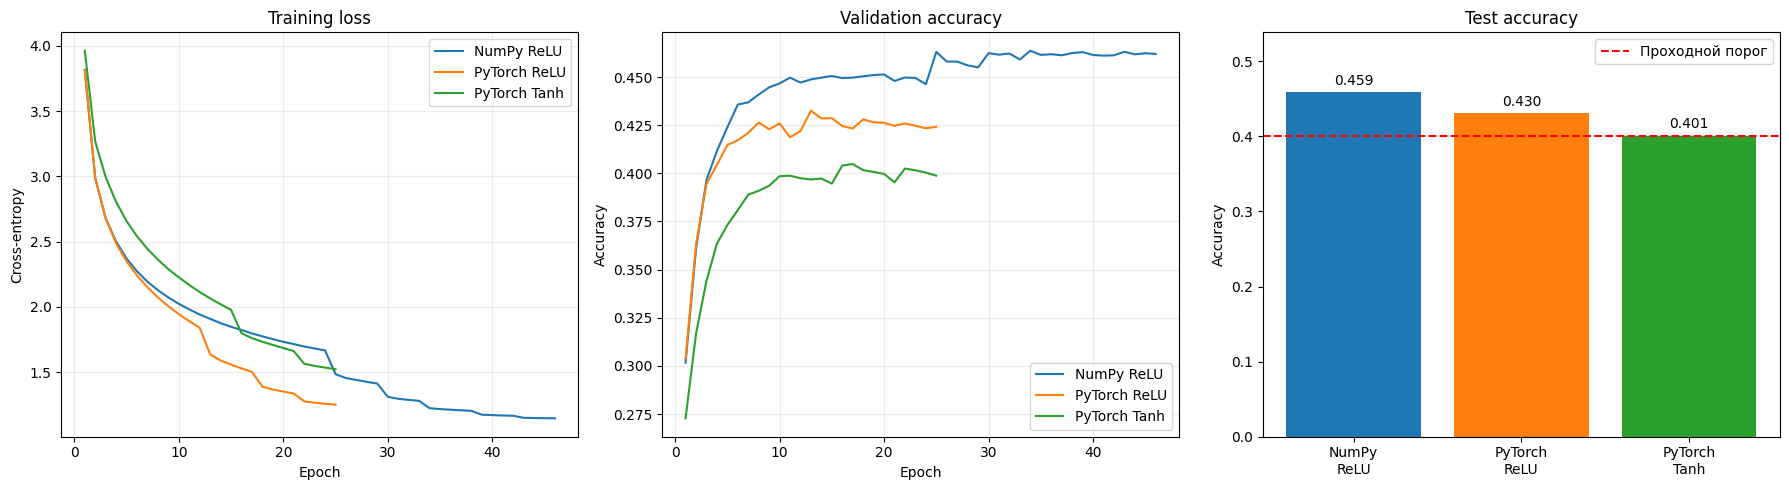

In [16]:
# Собираем итоги в единую таблицу без внешних зависимостей.
comparison_rows = [
    ("NumPy", "ReLU", numpy_val_acc, numpy_test_acc, np.mean(numpy_history["epoch_time"]), len(numpy_history["val_acc"])),
    ("PyTorch", "ReLU", torch_val_acc, torch_test_acc, np.mean(torch_history["epoch_time"]), len(torch_history["val_acc"])),
    ("PyTorch", "Tanh", tanh_val_acc, tanh_test_acc, np.mean(tanh_history["epoch_time"]), len(tanh_history["val_acc"])),
]
print(f"{'Implementation':<15} {'Activation':<11} {'Val acc':>9} {'Test acc':>10} {'Sec/epoch':>11} {'Epochs':>8}")
print("-" * 70)
for implementation, activation, val_acc, test_acc, seconds, epochs in comparison_rows:
    print(f"{implementation:<15} {activation:<11} {val_acc:>9.4f} {test_acc:>10.4f} {seconds:>11.2f} {epochs:>8d}")

# Графики показывают динамику loss/accuracy и итоговое качество на тесте.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for label, history in (("NumPy ReLU", numpy_history), ("PyTorch ReLU", torch_history), ("PyTorch Tanh", tanh_history)):
    epochs = np.arange(1, len(history["val_acc"]) + 1)
    axes[0].plot(epochs, history["train_loss"], label=label)
    axes[1].plot(epochs, history["val_acc"], label=label)
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[0].legend()
axes[1].legend()
axes[0].grid(alpha=0.25)
axes[1].grid(alpha=0.25)
names = [f"{row[0]}\n{row[1]}" for row in comparison_rows]
test_scores = [row[3] for row in comparison_rows]
bars = axes[2].bar(names, test_scores, color=["tab:blue", "tab:orange", "tab:green"])
axes[2].axhline(0.40, color="red", linestyle="--", label="Проходной порог")
axes[2].bar_label(bars, fmt="%.3f", padding=3)
axes[2].set(title="Test accuracy", ylabel="Accuracy", ylim=(0, max(test_scores) + 0.08))
axes[2].legend()
plt.tight_layout()
plt.show()

### Численная устойчивость и анализ

- В NumPy-softmax из logits вычитается максимум каждой строки: это не меняет вероятности, но не даёт `exp()` переполниться. Перед `log()` вероятность ограничивается снизу числом `1e-12`.
- Изображения и веса хранятся в `float32`; нормализация `[0, 1]` и He/Xavier initialization помогают не допустить взрыва или затухания сигнала.
- Батчевая обработка ограничивает пиковое потребление памяти. L2/weight decay, снижение learning rate и early stopping сдерживают наблюдаемое переобучение.
- Для основных обучений задан максимум `50` эпох — нижняя граница рекомендованного диапазона 50–100. NumPy-модель фактически выполнила 46 эпох, а PyTorch-модели — по 25: циклы завершились раньше только из-за `early stopping`, после отсутствия улучшения `val_acc` в течение заданного числа эпох. После остановки в каждую модель возвращены веса с лучшей валидационной точностью.
- ReLU не насыщается на положительной полуоси и обычно даёт более стабильный градиент в глубокой MLP. Tanh ограничивает выход диапазоном `[-1, 1]`, но на больших по модулю входах её градиент уменьшается.

**Вывод из эксперимента.** PyTorch ReLU достигла `test_acc = 0.4305`, а Tanh — `0.4010`. При одинаковых размерах слоёв ReLU дала прирост около 2.95 п.п. и быстрее набирала accuracy. Это согласуется с насыщением Tanh и ослаблением её градиента. NumPy ReLU показала лучший результ (`test_acc = 0.4585`), но её эпоха в среднем занимала 6.44 с против 3.23 с у PyTorch. Разница в accuracy не свидетельствует о преимуществе NumPy как фреймворка: здесь Adam и AdamW, начальные веса и порядок mini-batches не идентичны, поэтому точное равенство кривых не ожидается.

## 6. Инференс и сравнение качества

Реализуем единый по смыслу интерфейс предсказаний и разберём 10 фиксированных примеров из test.

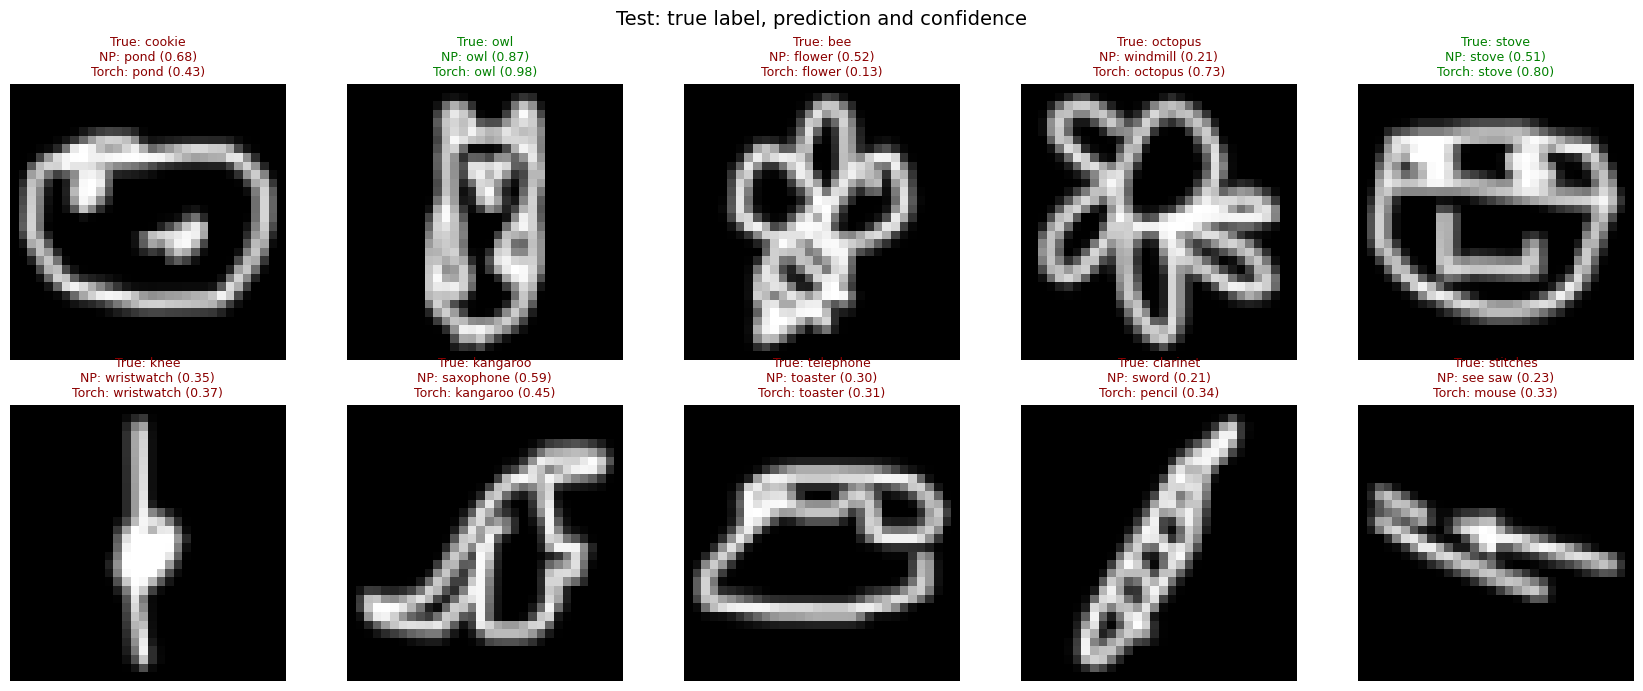

In [17]:
def predict_numpy(model, images):
    """Returns predicted classes and their probabilities for one image or a batch."""
    batch = np.asarray(images, dtype=np.float32)
    if batch.ndim == 2:
        batch = batch[np.newaxis, ...]
    logits = model.forward(batch.reshape(len(batch), -1))
    _, probabilities = model.softmax_cross_entropy(logits, np.zeros(len(batch), dtype=np.int64))
    predictions = probabilities.argmax(axis=1)
    confidence = probabilities[np.arange(len(batch)), predictions]
    return predictions, confidence


def predict_torch(model, images, device=DEVICE):
    """Returns predicted classes and their probabilities for one image or a batch."""
    batch = np.asarray(images, dtype=np.float32)
    if batch.ndim == 2:
        batch = batch[np.newaxis, ...]
    tensor = torch.from_numpy(batch.reshape(len(batch), -1)).to(device)
    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(tensor), dim=1)
        confidence, predictions = probabilities.max(dim=1)
    return predictions.cpu().numpy(), confidence.cpu().numpy()


# Выбираем 10 воспроизводимых примеров и получаем предсказания обеих моделей.
inference_indices = np.random.default_rng(SEED + 1).choice(len(X_test), size=10, replace=False)
inference_images = X_test[inference_indices]
inference_true = y_test[inference_indices]
numpy_predictions, numpy_confidence = predict_numpy(numpy_model, inference_images)
torch_predictions, torch_confidence = predict_torch(torch_model, inference_images)

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for axis, image, true_label, np_pred, np_prob, th_pred, th_prob in zip(
    axes.ravel(), inference_images, inference_true, numpy_predictions, numpy_confidence, torch_predictions, torch_confidence
):
    both_correct = np_pred == true_label and th_pred == true_label
    axis.imshow(image, cmap="gray", vmin=0, vmax=1)
    axis.set_title(
        f"True: {class_names[true_label]}\nNP: {class_names[np_pred]} ({np_prob:.2f})\nTorch: {class_names[th_pred]} ({th_prob:.2f})",
        color="green" if both_correct else "darkred",
        fontsize=9,
    )
    axis.axis("off")
plt.suptitle("Test: true label, prediction and confidence", fontsize=14)
plt.tight_layout()
plt.show()

### Визуализация предсказаний и анализ ошибок

Покажем десять тестовых изображений с истинными и предсказанными классами и вероятностями, затем оценим совпадения моделей и наиболее частые ошибки NumPy MLP.

In [18]:
from collections import Counter

# Считаем предсказания на всём test, чтобы анализ не зависел только от 10 показанных картинок.
all_numpy_predictions, _ = predict_numpy(numpy_model, X_test)
all_torch_predictions, _ = predict_torch(torch_model, X_test)

both_correct = np.sum((all_numpy_predictions == y_test) & (all_torch_predictions == y_test))
both_wrong = np.sum((all_numpy_predictions != y_test) & (all_torch_predictions != y_test))
disagreements = np.sum(all_numpy_predictions != all_torch_predictions)
print(f"Обе модели верны: {both_correct} из {len(y_test)}")
print(f"Обе модели ошиблись: {both_wrong} из {len(y_test)}")
print(f"Модели не согласны: {disagreements} из {len(y_test)}")

error_pairs = Counter(
    (class_names[true_label], class_names[predicted_label])
    for true_label, predicted_label in zip(y_test, all_numpy_predictions)
    if true_label != predicted_label
)
print("\nЧастые ошибки NumPy (истина → прогноз):")
for (true_name, predicted_name), count in error_pairs.most_common(5):
    print(f"  {true_name} → {predicted_name}: {count}")

Обе модели верны: 11908 из 34500
Обе модели ошиблись: 15738 из 34500
Модели не согласны: 16978 из 34500

Частые ошибки NumPy (истина → прогноз):
  bus → school bus: 31
  motorbike → bicycle: 30
  hurricane → tornado: 29
  cake → birthday cake: 28
  birthday cake → cake: 28


### Выводы и три шага для улучшения

Ошибки часто возникают между визуально близкими категориями и у очень схематичных или необычно нарисованных объектов. Вероятность ошибочного прогноза нередко низка, что показывает неуверенность модели.

1. **Перейти к CNN.** Свёрточные слои сохранят пространственную структуру штрихов, которую MLP теряет при flatten.
2. **Добавить аугментации штрихов.** Небольшие сдвиги, повороты и масштабирование сделают модель устойчивее к стилю и положению рисунка.
3. **Увеличить и точечно сбалансировать датасет.** Больше реальных вариантов для сложных и часто путаемых пар классов снизит variance и долю необычных тестовых примеров.